# Multi-Output Logistic Classification: Air Quality Pollutant Levels

This notebook uses the [UCI Air Quality dataset](https://archive.ics.uci.edu/dataset/360/air+quality) (hourly readings from a gas multisensor device in an Italian city, March 2004 to April 2005). It classifies three pollutants **at the same time** into Low / Medium / High concentration levels:

| Target | Reference measurement |
|---|---|
| `CO_class` | CO(GT): carbon monoxide, mg/m³ |
| `C6H6_class` | C6H6(GT): benzene, µg/m³ |
| `NOx_class` | NOx(GT): nitrogen oxides, ppb |

**Features:** the five low-cost metal-oxide sensor responses (`PT08.S1` to `PT08.S5`) and weather readings (temperature, relative and absolute humidity). The practical question is: *can the cheap sensors replace the expensive reference analyzers?*

**Model:** one logistic regression per target, wrapped in `MultiOutputClassifier`.

## 1. Imports

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, label_binarize
from sklearn.linear_model import LogisticRegression
from sklearn.multioutput import MultiOutputClassifier
from sklearn.model_selection import train_test_split
from sklearn.metrics import (accuracy_score, f1_score, roc_auc_score, roc_curve,
                             confusion_matrix, classification_report)

## 2. Load and Clean Data

The raw file uses `;` as the separator, `,` as the decimal mark, and **-200 as the missing-value code**. The file also ends with fully empty rows and empty columns, which are removed.

In [2]:
raw = pd.read_csv('AirQualityUCI.csv', sep=';', decimal=',', na_values=-200)
print("Raw shape:", raw.shape)

df = raw.dropna(axis=1, how='all')          # empty trailing columns
df = df.dropna(subset=['Date', 'Time'])      # empty trailing rows
print("After dropping empty rows/columns:", df.shape)

# Parse timestamps with the explicit format used in the file (e.g. '10/03/2004 18.00.00')
df['Datetime'] = pd.to_datetime(df['Date'] + ' ' + df['Time'], format='%d/%m/%Y %H.%M.%S')
df = df.drop(columns=['Date', 'Time']).sort_values('Datetime').reset_index(drop=True)
print("Time span:", df['Datetime'].min(), "to", df['Datetime'].max())

Raw shape: (9471, 17)
After dropping empty rows/columns: (9357, 15)
Time span: 2004-03-10 18:00:00 to 2005-04-04 14:00:00


In [3]:
missing = (df.isna().mean() * 100).round(1).sort_values(ascending=False)
print("Missing values (%):")
print(missing)

Missing values (%):
NMHC(GT)         90.2
CO(GT)           18.0
NOx(GT)          17.5
NO2(GT)          17.5
PT08.S1(CO)       3.9
C6H6(GT)          3.9
PT08.S2(NMHC)     3.9
PT08.S3(NOx)      3.9
PT08.S4(NO2)      3.9
PT08.S5(O3)       3.9
T                 3.9
RH                3.9
AH                3.9
Datetime          0.0
dtype: float64


**Cleaning decisions:**

* **`NMHC(GT)` is dropped.** About 90% of its values are missing, so imputing it would mostly create artificial data.
* **`NO2(GT)` is not used as a feature.** NO2 is one of the two components of NOx (NOx = NO + NO2), and it comes from the same reference analyzer, so using it to predict NOx would be target leakage. It also conflicts with the goal of using only low-cost sensors.
* **Rows with a missing target are dropped, not imputed.** Filling CO or NOx with the column mean would create fake labels (about 18% of rows), all landing in the same class.

In [4]:
target_sources = {'CO_class': 'CO(GT)', 'C6H6_class': 'C6H6(GT)', 'NOx_class': 'NOx(GT)'}
feature_cols = ['PT08.S1(CO)', 'PT08.S2(NMHC)', 'PT08.S3(NOx)', 'PT08.S4(NO2)', 'PT08.S5(O3)',
                'T', 'RH', 'AH']

n_before = len(df)
df = df.dropna(subset=list(target_sources.values())).reset_index(drop=True)
print(f"Dropped {n_before - len(df)} rows with a missing target -> {len(df)} rows remain")
print("Remaining missing values in features:", df[feature_cols].isna().sum().sum())

Dropped 2413 rows with a missing target -> 6944 rows remain


Remaining missing values in features: 0


## 3. Chronological Train/Test Split

The data is an **hourly time series**. Neighboring hours are almost identical, so a random split would put near-duplicate rows in both train and test and inflate the scores. Instead, the **first 80% of the timeline is used for training and the last 20% for testing**. This mirrors real deployment: train on the past, predict the future.

In [5]:
split_idx = int(len(df) * 0.80)
train_df = df.iloc[:split_idx].copy()
test_df = df.iloc[split_idx:].copy()
print("Train:", train_df['Datetime'].min().date(), "to", train_df['Datetime'].max().date(), f"({len(train_df)} rows)")
print("Test :", test_df['Datetime'].min().date(), "to", test_df['Datetime'].max().date(), f"({len(test_df)} rows)")

Train: 2004-03-10 to 2005-01-30 (5555 rows)
Test : 2005-01-30 to 2005-04-04 (1389 rows)


## 4. Create Class Labels (Bin Edges from Training Data Only)

Each pollutant is split into tertiles: Low, Medium, and High. The tertile **cut points are computed on the training period only** and then applied to the test period, so the test data has no influence on how the classes are defined.

In [6]:
class_names = ['Low', 'Medium', 'High']
bin_edges = {}

for target, source in target_sources.items():
    _, edges = pd.qcut(train_df[source], q=3, retbins=True)
    edges[0], edges[-1] = -np.inf, np.inf     # cover values outside the training range
    bin_edges[target] = edges
    for part in (train_df, test_df):
        part[target] = pd.cut(part[source], bins=edges, labels=False)   # 0 = Low, 1 = Medium, 2 = High

edges_table = pd.DataFrame({t: e[1:3] for t, e in bin_edges.items()},
                           index=['Low/Medium cut', 'Medium/High cut']).round(2)
print(edges_table)

                 CO_class  C6H6_class  NOx_class
Low/Medium cut        1.4         6.7     115.00
Medium/High cut       2.6        13.1     249.67


In [7]:
targets = list(target_sources.keys())
dist = pd.concat({
    'Train': train_df[targets].apply(lambda s: s.value_counts(normalize=True)).T,
    'Test': test_df[targets].apply(lambda s: s.value_counts(normalize=True)).T,
}, axis=1).round(3)
dist.columns = [f"{part} {class_names[int(c)]}" for part, c in dist.columns]
print("Class distribution (share of rows):")
print(dist)

Class distribution (share of rows):
            Train Low  Train Medium  Train High  Test Low  Test Medium  \
CO_class        0.349         0.341       0.311     0.427        0.324   
C6H6_class      0.337         0.333       0.330     0.531        0.281   
NOx_class       0.337         0.329       0.333     0.116        0.369   

            Test High  
CO_class        0.249  
C6H6_class      0.187  
NOx_class       0.515  


The test period (spring 2005) has a different class mix from the training period. Pollution is seasonal, so a chronological split also tests whether the model holds up under this **distribution shift**.

## 5. Exploratory Analysis

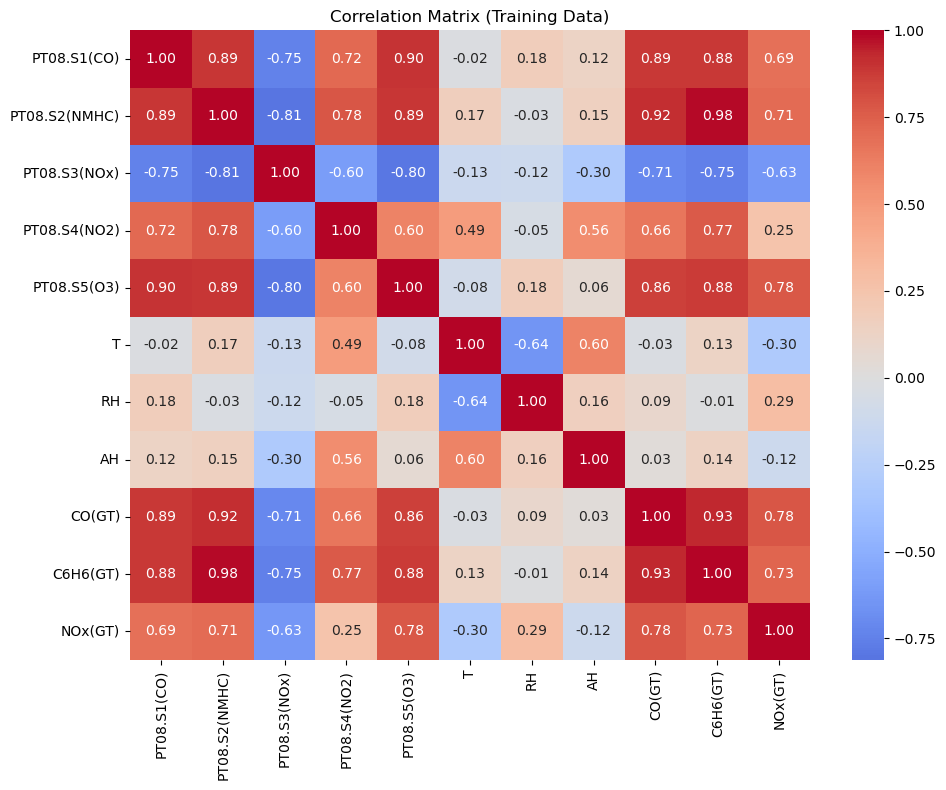

Correlation C6H6(GT) vs PT08.S2(NMHC): 0.983


In [8]:
corr = train_df[feature_cols + list(target_sources.values())].corr()
plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0)
plt.title('Correlation Matrix (Training Data)')
plt.tight_layout()
plt.show()

print(f"Correlation C6H6(GT) vs PT08.S2(NMHC): {corr.loc['C6H6(GT)', 'PT08.S2(NMHC)']:.3f}")

Benzene, `C6H6(GT)`, is almost a deterministic function of the `PT08.S2(NMHC)` sensor (correlation ≈ 0.98). Expect near-perfect accuracy for benzene. That reflects how closely this sensor tracks benzene, not a particularly clever model.

## 6. Model

Each target gets its own pipeline: median imputation, then standardization, then logistic regression. All of these are fitted on training data only.

In [9]:
X_train, X_test = train_df[feature_cols], test_df[feature_cols]
y_train, y_test = train_df[targets], test_df[targets]

base_pipeline = Pipeline([
    ('impute', SimpleImputer(strategy='median')),
    ('scale', StandardScaler()),
    ('logreg', LogisticRegression(max_iter=2000, class_weight='balanced')),
])
multi_lr = MultiOutputClassifier(base_pipeline)
multi_lr.fit(X_train, y_train)

y_pred = multi_lr.predict(X_test)
y_proba = multi_lr.predict_proba(X_test)   # list: one (n_samples, 3) array per target

## 7. Evaluation on the Future Test Period

In [10]:
rows = []
for i, t in enumerate(targets):
    rows.append({
        'Target': t,
        'Accuracy': accuracy_score(y_test[t], y_pred[:, i]),
        'Macro F1': f1_score(y_test[t], y_pred[:, i], average='macro'),
        'ROC AUC (OvR)': roc_auc_score(y_test[t], y_proba[i], multi_class='ovr'),
    })
results = pd.DataFrame(rows)
print(results.round(4).to_string(index=False))

for i, t in enumerate(targets):
    print(f"\n=== {t} ===")
    print(classification_report(y_test[t], y_pred[:, i], target_names=class_names, digits=3))

    Target  Accuracy  Macro F1  ROC AUC (OvR)
  CO_class    0.8423    0.8440         0.9508
C6H6_class    0.9820    0.9805         0.9993
 NOx_class    0.8387    0.8214         0.9553

=== CO_class ===
              precision    recall  f1-score   support

         Low      0.888     0.858     0.873       593
      Medium      0.739     0.818     0.776       450
        High      0.921     0.847     0.883       346

    accuracy                          0.842      1389
   macro avg      0.850     0.841     0.844      1389
weighted avg      0.848     0.842     0.844      1389


=== C6H6_class ===
              precision    recall  f1-score   support

         Low      0.996     0.981     0.988       738
      Medium      0.962     0.974     0.968       391
        High      0.974     0.996     0.985       260

    accuracy                          0.982      1389
   macro avg      0.977     0.984     0.980      1389
weighted avg      0.982     0.982     0.982      1389


=== NOx_class =

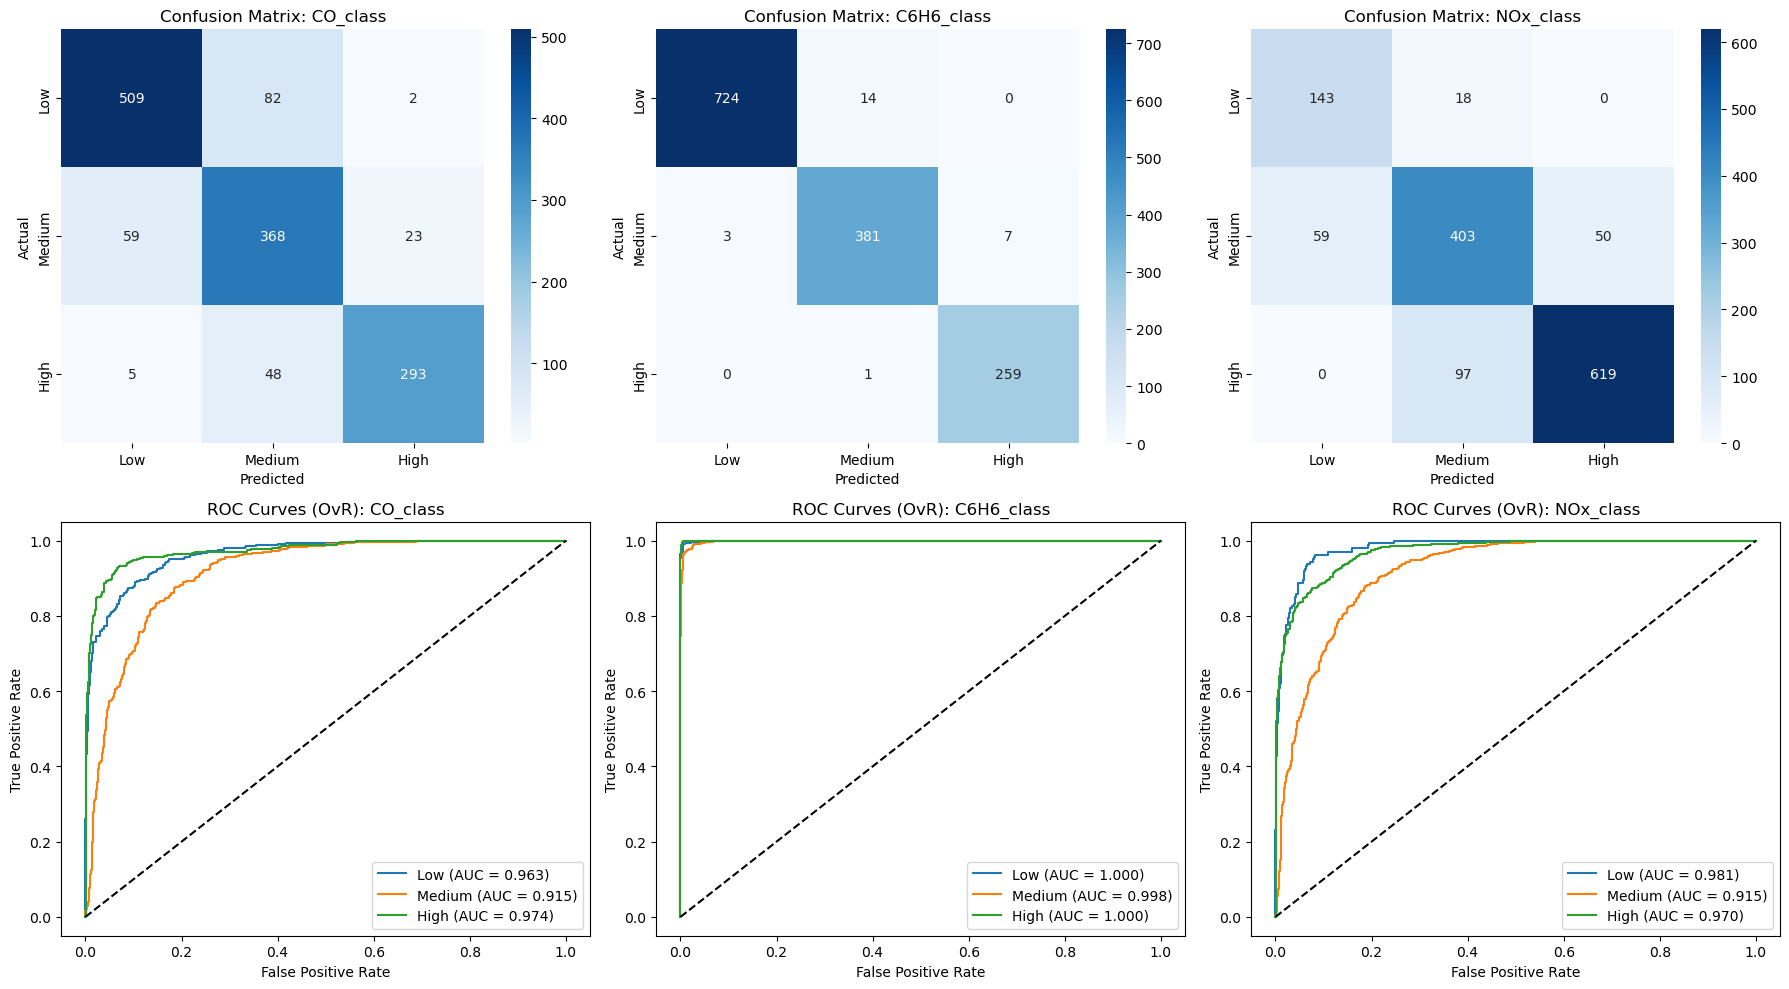

In [11]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for i, t in enumerate(targets):
    sns.heatmap(confusion_matrix(y_test[t], y_pred[:, i]), annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names, ax=axes[0, i])
    axes[0, i].set_title(f'Confusion Matrix: {t}')
    axes[0, i].set_xlabel('Predicted')
    axes[0, i].set_ylabel('Actual')

    y_bin = label_binarize(y_test[t], classes=[0, 1, 2])
    for j, cls in enumerate(class_names):
        fpr, tpr, _ = roc_curve(y_bin[:, j], y_proba[i][:, j])
        axes[1, i].plot(fpr, tpr, label=f'{cls} (AUC = {roc_auc_score(y_bin[:, j], y_proba[i][:, j]):.3f})')
    axes[1, i].plot([0, 1], [0, 1], 'k--')
    axes[1, i].set_title(f'ROC Curves (OvR): {t}')
    axes[1, i].set_xlabel('False Positive Rate')
    axes[1, i].set_ylabel('True Positive Rate')
    axes[1, i].legend()
plt.tight_layout()
plt.show()

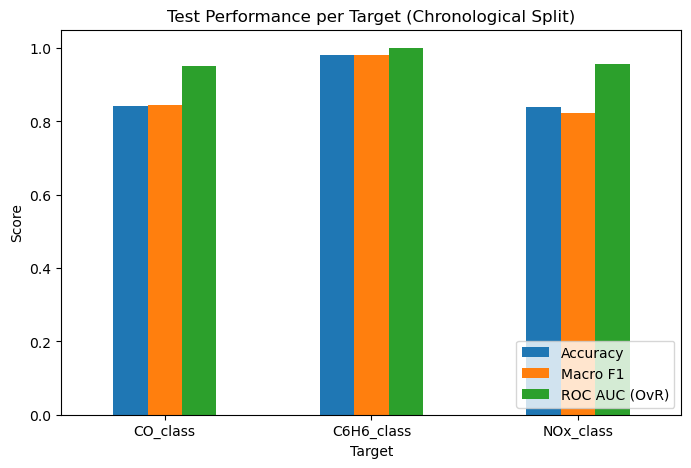

In [12]:
results.set_index('Target')[['Accuracy', 'Macro F1', 'ROC AUC (OvR)']].plot(kind='bar', figsize=(8, 5), rot=0)
plt.ylim(0, 1.05)
plt.ylabel('Score')
plt.title('Test Performance per Target (Chronological Split)')
plt.legend(loc='lower right')
plt.show()

## 8. Why the Chronological Split Matters

For comparison, the same model is trained on a **random** 80/20 split, with class edges recomputed on that random training set. This is the setup used in many tutorials.

In [13]:
rand_train, rand_test = train_test_split(df, test_size=0.20, random_state=42)
rand_train, rand_test = rand_train.copy(), rand_test.copy()
for t, source in target_sources.items():
    _, e = pd.qcut(rand_train[source], q=3, retbins=True)
    e[0], e[-1] = -np.inf, np.inf
    rand_train[t] = pd.cut(rand_train[source], bins=e, labels=False)
    rand_test[t] = pd.cut(rand_test[source], bins=e, labels=False)

rand_model = MultiOutputClassifier(base_pipeline).fit(rand_train[feature_cols], rand_train[targets])
rand_pred = rand_model.predict(rand_test[feature_cols])

compare = pd.DataFrame({
    'Target': targets,
    'Random split accuracy': [accuracy_score(rand_test[t], rand_pred[:, i]) for i, t in enumerate(targets)],
    'Chronological split accuracy': results['Accuracy'].values,
})
compare['Optimism'] = compare['Random split accuracy'] - compare['Chronological split accuracy']
print(compare.round(4).to_string(index=False))

    Target  Random split accuracy  Chronological split accuracy  Optimism
  CO_class                 0.8603                        0.8423     0.018
C6H6_class                 0.9820                        0.9820     0.000
 NOx_class                 0.8517                        0.8387     0.013


## 9. Feature Importance

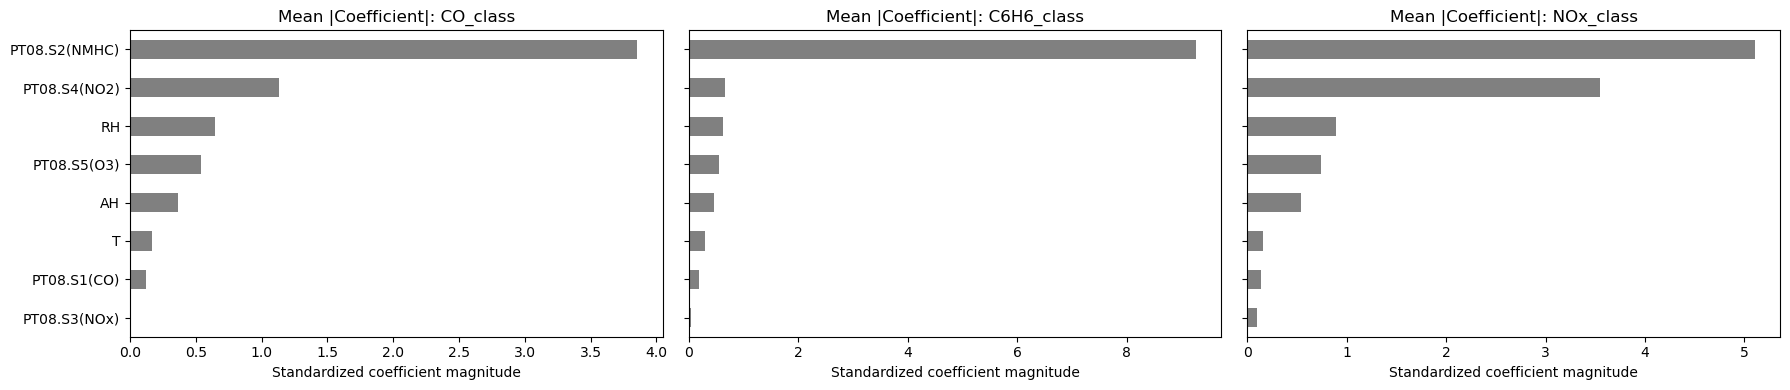

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4), sharey=True)
for i, t in enumerate(targets):
    coefs = np.abs(multi_lr.estimators_[i].named_steps['logreg'].coef_).mean(axis=0)
    pd.Series(coefs, index=feature_cols).sort_values().plot(kind='barh', ax=axes[i], color='gray')
    axes[i].set_title(f'Mean |Coefficient|: {t}')
    axes[i].set_xlabel('Standardized coefficient magnitude')
plt.tight_layout()
plt.show()

## 10. Conclusion

Test results on the final ~2 months of data (chronological split):

| Target | Accuracy | Macro F1 | ROC AUC (OvR) |
|---|---|---|---|
| CO_class | 0.842 | 0.844 | 0.951 |
| C6H6_class | 0.982 | 0.981 | 0.999 |
| NOx_class | 0.839 | 0.821 | 0.955 |

* **The low-cost sensors can classify pollutant levels well.** Accuracy is about 84% for CO and NOx on future data, despite a shift in the class mix between seasons.
* **Benzene is near-perfect** because the `PT08.S2(NMHC)` sensor tracks benzene almost exactly (correlation 0.98), not because of the model.
* **Data issues fixed compared with the earlier version:**
  * Timestamps are now parsed correctly. Previously every value failed to parse.
  * Empty padding rows are removed.
  * `NMHC(GT)` (90% missing) is dropped.
  * Rows with missing targets are dropped instead of being mean-imputed. Mean imputation had created fake labels for about 18% of rows.
  * `NO2(GT)` is excluded from the features, because it is a component of the NOx target.
* **Effect of the split:** a random split inflates accuracy by only 1 to 2 points here. The larger effect came from removing the fabricated labels. The chronological split is still the honest choice for time-series data.